# Q4. SVMs and clustering (bonus: 25 marks)

We use the same CIFAR-10 split as the earlier questions, with seed 26001. The representation is the frozen clean autoencoder bottleneck selected by validation MSE in Q3. A standard scaler is fitted on the training subset and kept unchanged for both SVMs and clustering.

In [1]:
from pathlib import Path
import time
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from IPython.display import display
import joblib

SEED = 26001
RESULTS = Path("results_q4")
RESULTS.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_FOLDER = Path("data")
BATCH_SIZE = 128
SUBSET_SIZE = 3000
C_VALUES = [0.001, 0.01, 0.1, 1.0, 10.0]
KERNELS = ["linear", "rbf", "poly"]
CLUSTER_COUNTS = [5, 10, 15, 20]

print("Device:", DEVICE)
print("Seed:", SEED)
print("Training subset size:", SUBSET_SIZE)

Device: cpu
Seed: 26001
Training subset size: 3000


## Q4. Fixed representation and training subset

The Q3-selected encoder has a **512-dimensional bottleneck**. Before model selection we take one fixed, stratified subset of 3,000 images from the 45,000 training images: 300 per class. The same subset is used for every SVM comparison and for clustering. The validation set contains 5,000 images.

In [2]:
q3_table_path = Path("results_q3/clean_validation_results.csv")
if not q3_table_path.exists():
    raise FileNotFoundError("Q3 results not found. Put this notebook in the Q1–Q3 folder and finish Q3 training first.")
q3_table = pd.read_csv(q3_table_path)
selected_row = q3_table.loc[q3_table["Validation MSE"].idxmin()]
bottleneck_size = int(selected_row["Bottleneck size"])
encoder_path = Path("results_q3") / f"clean_{bottleneck_size}_best.pt"
if not encoder_path.exists():
    raise FileNotFoundError(f"Missing Q3 checkpoint: {encoder_path}")
print("Q3 validation-selected bottleneck:", bottleneck_size)
print("Q3 validation MSE:", selected_row["Validation MSE"])

class ConvAutoencoder(nn.Module):
    # Same architecture as the Q3 notebook.
    def __init__(self, bottleneck_size):
        super().__init__()
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(), nn.Flatten()
        )
        self.to_bottleneck = nn.Sequential(nn.Linear(64 * 4 * 4, bottleneck_size), nn.ReLU())
        self.from_bottleneck = nn.Sequential(nn.Linear(bottleneck_size, 64 * 4 * 4), nn.ReLU())
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1), nn.Sigmoid()
        )
    def encode(self, x):
        return self.to_bottleneck(self.encoder_conv(x))
    def forward(self, x):
        z = self.encode(x)
        return self.decoder_conv(self.from_bottleneck(z).reshape(-1, 64, 4, 4))

checkpoint = torch.load(encoder_path, map_location=DEVICE, weights_only=False)
assert checkpoint["bottleneck"] == bottleneck_size and not checkpoint["denoising"]
encoder = ConvAutoencoder(bottleneck_size).to(DEVICE)
encoder.load_state_dict(checkpoint["state_dict"])
encoder.eval()
for parameter in encoder.parameters():
    parameter.requires_grad = False
print("Loaded Q3 checkpoint:", encoder_path)

train_data = datasets.CIFAR10(root=str(DATA_FOLDER), train=True,
                              download=True, transform=transforms.ToTensor())
labels = np.asarray(train_data.targets)
train_indices, val_indices = train_test_split(
    np.arange(len(train_data)), train_size=45000, test_size=5000,
    random_state=SEED, stratify=labels
)
q3_split_path = Path("results_q3/split_seed_26001.npz")
if q3_split_path.exists():
    with np.load(q3_split_path) as split:
        assert np.array_equal(train_indices, split["train_indices"]), "Q3 training split differs."
        assert np.array_equal(val_indices, split["val_indices"]), "Q3 validation split differs."
    print("Split matches Q3.")

subset_indices, _ = train_test_split(
    train_indices, train_size=SUBSET_SIZE, random_state=SEED, stratify=labels[train_indices]
)
np.savez(RESULTS / "fixed_indices.npz", train_subset_indices=subset_indices,
         val_indices=val_indices, seed=SEED)
print("Training subset:", len(subset_indices), "| validation:", len(val_indices))
print("Subset images per class:", np.bincount(labels[subset_indices], minlength=10))

Q3 validation-selected bottleneck: 512
Q3 validation MSE: 0.004913396310309569
Loaded Q3 checkpoint: results_q3\clean_512_best.pt
Split matches Q3.
Training subset: 3000 | validation: 5000
Subset images per class: [300 300 300 300 300 300 300 300 300 300]


## Q4. Extract the fixed features

The encoder weights are frozen. We fit the feature scaler on the training subset only and apply it to validation and test features without refitting.

In [3]:
class ImageSubset(Dataset):
    def __init__(self, base_data, indices):
        self.base_data = base_data
        self.indices = indices
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, item):
        return self.base_data[int(self.indices[item])]

@torch.no_grad()
def extract_features(base_data, indices):
    loader = DataLoader(ImageSubset(base_data, indices), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)
    feature_batches, label_batches = [], []
    encoder.eval()
    for images, labels_batch in loader:
        features = encoder.encode(images.to(DEVICE))
        feature_batches.append(features.cpu().numpy())
        label_batches.append(labels_batch.numpy())
    return np.concatenate(feature_batches), np.concatenate(label_batches)

print("Extracting training features...")
raw_train, y_train = extract_features(train_data, subset_indices)
print("Extracting validation features...")
raw_val, y_val = extract_features(train_data, val_indices)
scaler = StandardScaler()
X_train = scaler.fit_transform(raw_train)
X_val = scaler.transform(raw_val)
joblib.dump(scaler, RESULTS / "feature_scaler.joblib")
print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)

Extracting training features...
Extracting validation features...
Training feature shape: (3000, 512)
Validation feature shape: (5000, 512)


## Q4(a). Effect of C and kernel choice

We compare linear, RBF and degree-3 polynomial SVM kernels with C values 0.001, 0.01, 0.1, 1 and 10. The values span four orders of magnitude. Every setting uses the same representation, training subset and validation set. We record training accuracy, validation accuracy and the fraction of training points that become support vectors; the setting with the highest validation accuracy is selected.

In [4]:
sweep_rows = []
best_val_accuracy = -1.0
best_svm = None
best_settings = None

for kernel in KERNELS:
    for c_value in C_VALUES:
        start = time.time()
        model = SVC(C=c_value, kernel=kernel, gamma="scale", degree=3,
                    decision_function_shape="ovo")
        model.fit(X_train, y_train)
        train_accuracy = accuracy_score(y_train, model.predict(X_train))
        val_accuracy = accuracy_score(y_val, model.predict(X_val))
        support_fraction = len(model.support_) / len(y_train)
        elapsed = time.time() - start
        sweep_rows.append({"Kernel": kernel, "C": c_value,
                           "Training accuracy": train_accuracy,
                           "Validation accuracy": val_accuracy,
                           "Support vector fraction": support_fraction,
                           "Seconds": elapsed})
        print(f"{kernel:6s} | C={c_value:6g} | train={train_accuracy:.4f} | "
              f"val={val_accuracy:.4f} | support={support_fraction:.4f} | {elapsed:.1f}s", flush=True)
        # Strict > makes ties go to the first setting in the fixed loop above.
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_svm = model
            best_settings = {"Kernel": kernel, "C": c_value, "Validation accuracy": val_accuracy}

sweep_table = pd.DataFrame(sweep_rows)
sweep_table.to_csv(RESULTS / "svm_sweep.csv", index=False)
joblib.dump(best_svm, RESULTS / "selected_svm.joblib")
pd.DataFrame([best_settings]).to_csv(RESULTS / "selected_svm_settings.csv", index=False)
print("\nSelected using validation accuracy:", best_settings)
display(sweep_table.round(4))

linear | C= 0.001 | train=0.4517 | val=0.3620 | support=0.9733 | 10.8s
linear | C=  0.01 | train=0.5687 | val=0.3760 | support=0.9300 | 9.4s
linear | C=   0.1 | train=0.7090 | val=0.3546 | support=0.8943 | 10.4s
linear | C=     1 | train=0.8293 | val=0.3382 | support=0.8667 | 15.3s
linear | C=    10 | train=0.9320 | val=0.3184 | support=0.8627 | 49.6s
rbf    | C= 0.001 | train=0.3247 | val=0.2646 | support=1.0000 | 15.7s
rbf    | C=  0.01 | train=0.3247 | val=0.2646 | support=1.0000 | 15.6s
rbf    | C=   0.1 | train=0.3703 | val=0.2984 | support=0.9987 | 15.4s
rbf    | C=     1 | train=0.7733 | val=0.4164 | support=0.9770 | 13.7s
rbf    | C=    10 | train=0.9967 | val=0.4182 | support=0.9857 | 14.4s
poly   | C= 0.001 | train=0.1130 | val=0.1066 | support=1.0000 | 10.7s
poly   | C=  0.01 | train=0.1223 | val=0.1078 | support=0.9997 | 10.6s
poly   | C=   0.1 | train=0.2650 | val=0.1770 | support=0.9973 | 12.2s
poly   | C=     1 | train=0.7663 | val=0.3200 | support=0.9820 | 12.0s
poly   

,Kernel,C,Training accuracy,Validation accuracy,Support vector fraction,Seconds
0,linear,0.001,0.4517,0.3620,0.9733,10.8321
1,linear,0.010,0.5687,0.3760,0.9300,9.3542
2,linear,0.100,0.7090,0.3546,0.8943,10.4160
3,linear,1.000,0.8293,0.3382,0.8667,15.2768
4,linear,10.000,0.9320,0.3184,0.8627,49.5991
5,rbf,0.001,0.3247,0.2646,1.0000,15.6772
6,rbf,0.010,0.3247,0.2646,1.0000,15.5945
7,rbf,0.100,0.3703,0.2984,0.9987,15.3946
8,rbf,1.000,0.7733,0.4164,0.9770,13.6735
9,rbf,10.000,0.9967,0.4182,0.9857,14.3651


### Q4(a). Validation results and model selection

The highest validation accuracy was **41.82%** for the **RBF kernel with C = 10**. Its training accuracy was **99.67%**, and **98.57%** of training points were support vectors. The large train–validation gap is consistent with overfitting on this subset. At the other extreme, the polynomial kernel with C = 0.001 reached only **11.30%** training and **10.66%** validation accuracy, consistent with underfitting. These conclusions refer to the observed training and validation results, not just the selected model.

### Q4(a). Validation accuracy and support-vector fraction

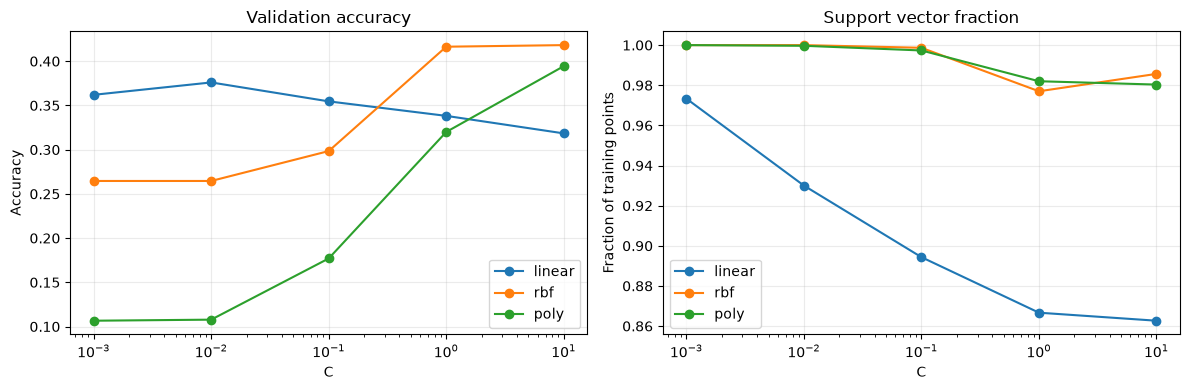

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kernel in KERNELS:
    rows = sweep_table[sweep_table["Kernel"] == kernel]
    axes[0].semilogx(rows["C"], rows["Validation accuracy"], marker="o", label=kernel)
    axes[1].semilogx(rows["C"], rows["Support vector fraction"], marker="o", label=kernel)
axes[0].set(title="Validation accuracy", xlabel="C", ylabel="Accuracy")
axes[1].set(title="Support vector fraction", xlabel="C", ylabel="Fraction of training points")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "svm_sweep.png", dpi=160, bbox_inches="tight")
plt.show()

## Q4(c). Choose clusters without labels

K-means is fitted to the same scaled training representations with candidate cluster counts 5, 10, 15 and 20. The number of clusters is selected using validation silhouette score without class labels. The chosen fitted model is then used to assign clusters to the test representations.

In [6]:
cluster_rows = []
best_silhouette = -np.inf
best_cluster_model = None
best_k = None
for k in CLUSTER_COUNTS:
    start = time.time()
    cluster_model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    cluster_model.fit(X_train)  # No class labels are passed here.
    val_clusters = cluster_model.predict(X_val)
    if len(np.unique(val_clusters)) < 2:
        score = np.nan
    else:
        score = silhouette_score(X_val, val_clusters, sample_size=min(1500, len(X_val)),
                                 random_state=SEED)
    cluster_rows.append({"Clusters": k, "Validation silhouette": score,
                         "Training inertia": cluster_model.inertia_, "Seconds": time.time() - start})
    print(f"K={k:2d} | validation silhouette={score:.4f}", flush=True)
    if np.isfinite(score) and score > best_silhouette:
        best_silhouette = score
        best_k = k
        best_cluster_model = cluster_model

if best_cluster_model is None:
    raise ValueError("No valid silhouette score. Inspect the feature representation and cluster assignments.")
cluster_selection = pd.DataFrame(cluster_rows)
cluster_selection.to_csv(RESULTS / "cluster_selection.csv", index=False)
joblib.dump(best_cluster_model, RESULTS / "selected_kmeans.joblib")
print("Selected number of clusters using validation data:", best_k)
display(cluster_selection.round(4))

K= 5 | validation silhouette=0.0536
K=10 | validation silhouette=0.0102
K=15 | validation silhouette=0.0017
K=20 | validation silhouette=-0.0012
Selected number of clusters using validation data: 5


,Clusters,Validation silhouette,Training inertia,Seconds
0,5,0.0536,668199.8750,1.3927
1,10,0.0102,625260.1875,1.5175
2,15,0.0017,601650.5000,2.0882
3,20,-0.0012,586086.3125,2.3154


### Q4(c). Validation selection

The validation silhouette scores were **0.0536, 0.0102, 0.0017 and −0.0012** for 5, 10, 15 and 20 clusters, respectively. We selected **5 clusters** because it had the highest validation silhouette. The small score suggests weak separation under this metric; it does not guarantee agreement with the ten class labels.

## Q4. Final test evaluation

The SVM and clustering choices are fixed before evaluation. Test labels are used only after predictions and cluster assignments are produced.

In [7]:
test_data = datasets.CIFAR10(root=str(DATA_FOLDER), train=False,
                             download=True, transform=transforms.ToTensor())
test_indices = np.arange(len(test_data))
print("Extracting official test features...")
raw_test, y_test = extract_features(test_data, test_indices)
X_test = scaler.transform(raw_test)

# Predictions and cluster assignments do not use test labels.
svm_predictions = best_svm.predict(X_test)
test_pair_scores = best_svm.decision_function(X_test)
test_clusters = best_cluster_model.predict(X_test)

# Labels are used only now for test evaluation and descriptive analysis.
test_accuracy = accuracy_score(y_test, svm_predictions)
test_ari = adjusted_rand_score(y_test, test_clusters)
test_nmi = normalized_mutual_info_score(y_test, test_clusters)
print(f"Selected SVM test accuracy: {test_accuracy:.4f}")
print(f"Test ARI: {test_ari:.4f}")
print(f"Test NMI: {test_nmi:.4f}")

summary = pd.DataFrame([{"Kernel": best_settings["Kernel"], "C": best_settings["C"],
                         "SVM test accuracy": test_accuracy, "Clusters": best_k,
                         "Test ARI": test_ari, "Test NMI": test_nmi}])
summary.to_csv(RESULTS / "final_test_summary.csv", index=False)
class_names = train_data.classes
contingency = pd.crosstab(pd.Series(test_clusters, name="Cluster"),
                          pd.Series([class_names[y] for y in y_test], name="True class"))
contingency = contingency.reindex(index=range(best_k), columns=class_names, fill_value=0)
contingency.to_csv(RESULTS / "test_cluster_class_contingency.csv")
print("Test cluster-to-class contingency table:")
display(contingency)

Extracting official test features...
Selected SVM test accuracy: 0.4245
Test ARI: 0.0313
Test NMI: 0.0605
Test cluster-to-class contingency table:


True class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
Cluster,,,,,,,,,,
0,311,207,106,80,56,96,31,174,412,414
1,54,192,91,134,65,135,107,91,61,95
2,115,373,285,372,332,410,422,400,141,259
3,386,115,465,341,534,310,380,279,358,122
4,134,113,53,73,13,49,60,56,28,110


### Q4(a) and Q4(c). Test results

The validation-selected RBF SVM obtained **42.45% test accuracy**. The selected 5-cluster K-means model obtained **ARI = 0.0313** and **NMI = 0.0605** on the test set. The contingency table shows that clusters contain mixtures of classes; cluster numbers themselves have no class meaning.

## Q4(b). Difficult class pairs and decision boundaries

We select the three class pairs with the most two-way test mistakes. For each pair, the plots show training support vectors used by that pairwise classifier and test images with the smallest absolute pairwise decision scores. The scores are signed SVM decision values, not probabilities; near zero means close to that pair's decision boundary in score space.

Three pairs with the most two-way test mistakes:


,Class A,Class B,Class A ID,Class B ID,A predicted B,B predicted A,Two-way mistakes
25,cat,dog,3,5,197,219,416
16,automobile,truck,1,9,166,224,390
18,bird,deer,2,4,123,174,297


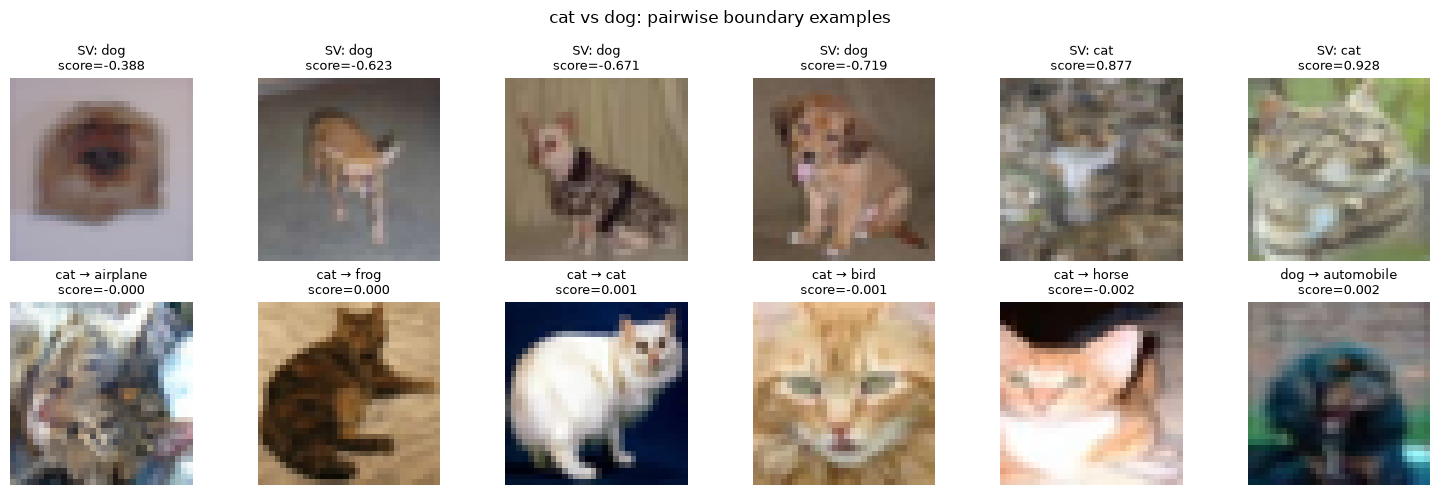

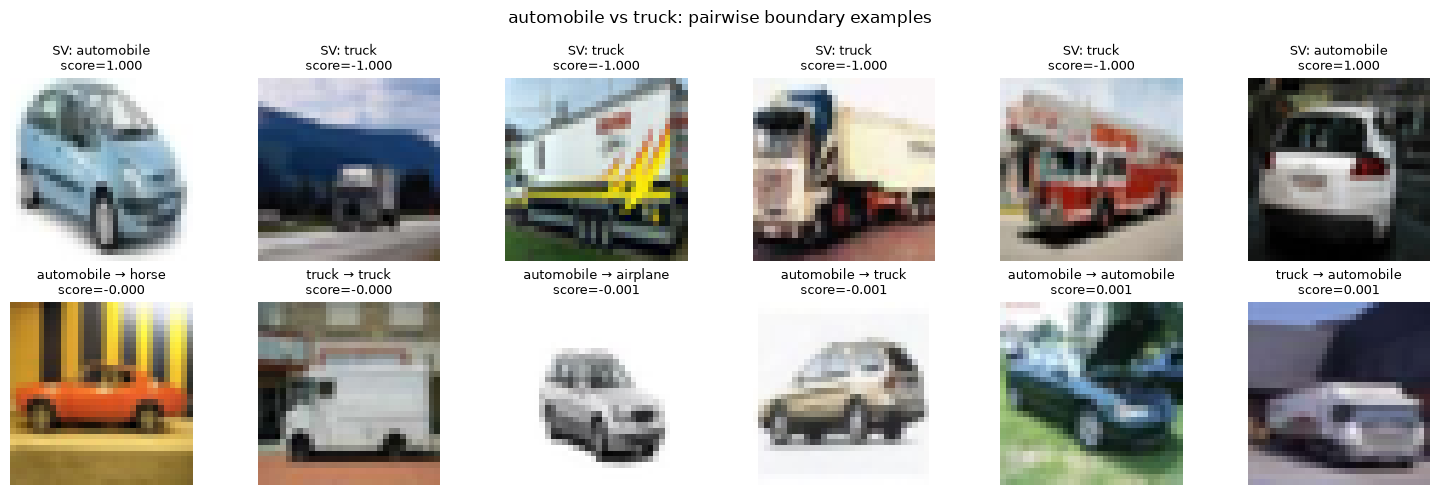

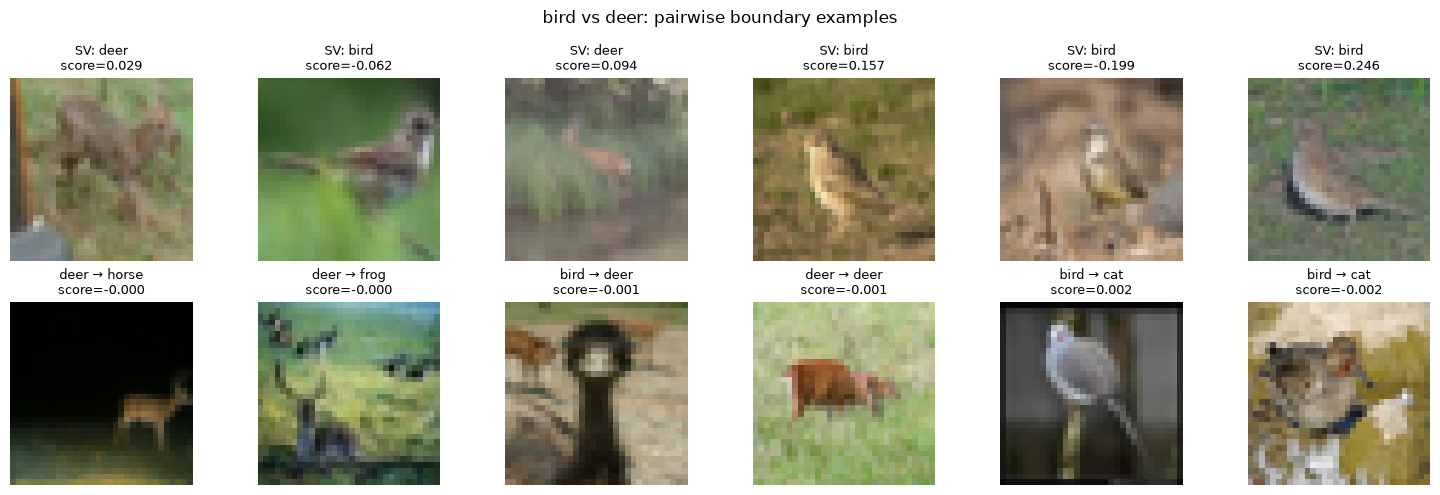

,Pair,Type,Dataset index,True class,Prediction,Pairwise score
0,cat vs dog,train support vector,2017,dog,,-0.387629
1,cat vs dog,near-boundary test,3180,cat,airplane,-0.000261
2,cat vs dog,train support vector,6694,dog,,-0.622692
3,cat vs dog,near-boundary test,6175,cat,frog,0.000385
4,cat vs dog,train support vector,24238,dog,,-0.671257
5,cat vs dog,near-boundary test,565,cat,cat,0.000627
6,cat vs dog,train support vector,2730,dog,,-0.718525
7,cat vs dog,near-boundary test,8302,cat,bird,-0.000939
8,cat vs dog,train support vector,11333,cat,,0.876509
9,cat vs dog,near-boundary test,2565,cat,horse,-0.001809


In [8]:
class_ids = list(best_svm.classes_)
class_pairs = list(itertools.combinations(class_ids, 2))
test_confusion = confusion_matrix(y_test, svm_predictions, labels=class_ids)
confusion_frame = pd.DataFrame(test_confusion, index=class_names, columns=class_names)
confusion_frame.to_csv(RESULTS / "svm_test_confusion_matrix.csv")

pair_rows = []
for i, j in class_pairs:
    mistakes = int(test_confusion[i, j] + test_confusion[j, i])
    pair_rows.append({"Class A": class_names[i], "Class B": class_names[j],
                      "Class A ID": i, "Class B ID": j,
                      "A predicted B": int(test_confusion[i, j]),
                      "B predicted A": int(test_confusion[j, i]),
                      "Two-way mistakes": mistakes})
pair_table = pd.DataFrame(pair_rows).sort_values("Two-way mistakes", ascending=False)
pair_table.to_csv(RESULTS / "all_class_pair_errors.csv", index=False)
difficult_pairs = pair_table.head(3)
print("Three pairs with the most two-way test mistakes:")
display(difficult_pairs)
if (difficult_pairs["Two-way mistakes"] == 0).any():
    print("Note: at least one selected pair has zero direct mistakes; interpret it accordingly.")

def pair_support_positions(model, class_a, class_b):
    # scikit-learn stores support vectors in class blocks. For pair i < j,
    # class i uses dual_coef_[j-1] and class j uses dual_coef_[i].
    i = list(model.classes_).index(class_a)
    j = list(model.classes_).index(class_b)
    if i > j:
        i, j = j, i
    ends = np.cumsum(model.n_support_)
    starts = np.r_[0, ends[:-1]]
    a_positions = np.arange(starts[i], ends[i])
    b_positions = np.arange(starts[j], ends[j])
    a_positions = a_positions[np.abs(model.dual_coef_[j - 1, a_positions]) > 1e-12]
    b_positions = b_positions[np.abs(model.dual_coef_[i, b_positions]) > 1e-12]
    return np.r_[a_positions, b_positions]

example_rows = []
for _, row in difficult_pairs.iterrows():
    a, b = int(row["Class A ID"]), int(row["Class B ID"])
    pair_column = class_pairs.index((a, b))

    # Map support-vector positions to rows in the original 3,000-example subset.
    support_positions = pair_support_positions(best_svm, a, b)
    support_train_rows = best_svm.support_[support_positions]
    if len(support_train_rows) == 0:
        print("No pair-specific support vectors found for", class_names[a], class_names[b])
        continue
    support_scores = best_svm.decision_function(X_train[support_train_rows])[:, pair_column]
    chosen_support = np.argsort(np.abs(support_scores))[:6]
    candidates = np.flatnonzero((y_test == a) | (y_test == b))
    chosen_test = candidates[np.argsort(np.abs(test_pair_scores[candidates, pair_column]))[:6]]

    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    fig.suptitle(f"{class_names[a]} vs {class_names[b]}: pairwise boundary examples")
    for col in range(6):
        axes[0, col].axis("off")
        axes[1, col].axis("off")
        if col < len(chosen_support):
            k = chosen_support[col]
            subset_row = support_train_rows[k]
            dataset_index = int(subset_indices[subset_row])
            image, true_label = train_data[dataset_index]
            score = float(support_scores[k])
            axes[0, col].imshow(image.permute(1, 2, 0))
            axes[0, col].set_title(f"SV: {class_names[true_label]}\nscore={score:.3f}", fontsize=9)
            example_rows.append({"Pair": f"{class_names[a]} vs {class_names[b]}", "Type": "train support vector",
                                 "Dataset index": dataset_index, "True class": class_names[true_label],
                                 "Prediction": "", "Pairwise score": score})
        if col < len(chosen_test):
            idx = int(chosen_test[col])
            image, true_label = test_data[idx]
            score = float(test_pair_scores[idx, pair_column])
            predicted = int(svm_predictions[idx])
            axes[1, col].imshow(image.permute(1, 2, 0))
            axes[1, col].set_title(f"{class_names[true_label]} → {class_names[predicted]}\nscore={score:.3f}", fontsize=9)
            example_rows.append({"Pair": f"{class_names[a]} vs {class_names[b]}", "Type": "near-boundary test",
                                 "Dataset index": idx, "True class": class_names[true_label],
                                 "Prediction": class_names[predicted], "Pairwise score": score})
    fig.tight_layout()
    fig.savefig(RESULTS / f"boundary_{class_names[a]}_{class_names[b]}.png", dpi=160, bbox_inches="tight")
    plt.show()

example_table = pd.DataFrame(example_rows)
example_table.to_csv(RESULTS / "pair_support_and_boundary_examples.csv", index=False)
display(example_table)

### Q4(b). Answer: three difficult class pairs

The largest two-way test confusions were **cat–dog: 416** (197 cats predicted as dogs and 219 dogs predicted as cats), **automobile–truck: 390** (166 and 224), and **bird–deer: 297** (123 and 174). The images above show the selected pair-specific training support vectors and near-boundary test examples with their scores.

For example, a cat test image has a cat–dog score of approximately **−0.000261**, and a bird test image has a bird–deer score of approximately **−0.001211**; both are close to their respective pairwise boundaries in decision-score space. Some near-boundary images are predicted as a third class because the final multiclass prediction combines several pairwise decisions. These observations are consistent with ambiguity in the learned representation; the score alone does not establish a physical image-space distance.

## Q4(c). Compare classification and clustering

For each class pair, **direct SVM confusion** is the fraction of the two classes' examples predicted as the other class. **Cluster distribution overlap** compares how similarly those two classes are distributed across clusters. These quantities measure different things, so we interpret them together with each class's recall and the contingency table.

In [9]:
cluster_distributions = np.zeros((len(class_ids), best_k))
for class_id in class_ids:
    class_clusters = test_clusters[y_test == class_id]
    cluster_distributions[class_id] = np.bincount(class_clusters, minlength=best_k) / len(class_clusters)

comparison_rows = []
for a, b in class_pairs:
    total_pair_examples = int((y_test == a).sum() + (y_test == b).sum())
    pair_errors = int(test_confusion[a, b] + test_confusion[b, a])
    overlap = np.minimum(cluster_distributions[a], cluster_distributions[b]).sum()
    comparison_rows.append({"Class A": class_names[a], "Class B": class_names[b],
                            "Two-way SVM errors": pair_errors,
                            "SVM direct confusion rate": pair_errors / total_pair_examples,
                            "Cluster distribution overlap": overlap,
                            "Class A SVM recall": test_confusion[a, a] / test_confusion[a].sum(),
                            "Class B SVM recall": test_confusion[b, b] / test_confusion[b].sum()})
comparison = pd.DataFrame(comparison_rows)
comparison = comparison.sort_values(["SVM direct confusion rate", "Cluster distribution overlap"],
                                    ascending=[True, False])
comparison.to_csv(RESULTS / "classification_clustering_pair_comparison.csv", index=False)

# A candidate is descriptive: inspect its absolute numbers and class recalls before concluding.
low_confusion = comparison[comparison["SVM direct confusion rate"] <= 0.10]
if len(low_confusion):
    candidate = low_confusion.sort_values("Cluster distribution overlap", ascending=False).head(1)
    print("Candidate with at most 10% direct SVM confusion and the highest cluster overlap:")
else:
    candidate = comparison.head(1)
    print("No pair has direct confusion <= 10%; showing the least-confused pair instead:")
display(candidate.round(4))
print("All class-pair comparisons:")
display(comparison.round(4))

Candidate with at most 10% direct SVM confusion and the highest cluster overlap:


,Class A,Class B,Two-way SVM errors,SVM direct confusion rate,Cluster distribution overlap,Class A SVM recall,Class B SVM recall
36,dog,horse,191,0.0955,0.915,0.317,0.411


All class-pair comparisons:


,Class A,Class B,Two-way SVM errors,SVM direct confusion rate,Cluster distribution overlap,Class A SVM recall,Class B SVM recall
40,frog,ship,25,0.0125,0.619,0.439,0.538
42,horse,ship,33,0.0165,0.683,0.411,0.538
34,deer,truck,33,0.0165,0.515,0.320,0.478
23,bird,truck,38,0.0190,0.631,0.319,0.478
5,airplane,frog,43,0.0215,0.640,0.545,0.439
11,automobile,deer,46,0.0230,0.581,0.570,0.320
38,dog,truck,49,0.0245,0.621,0.317,0.478
33,deer,ship,52,0.0260,0.629,0.320,0.538
41,frog,truck,57,0.0285,0.567,0.439,0.478
13,automobile,frog,58,0.0290,0.686,0.570,0.439


### Q4(c). Answer: classification versus clustering

For **dog and horse**, the SVM made **191 direct two-way errors among 2,000 test images**, a direct confusion rate of **9.55%**. Their cluster-distribution overlap was **0.915**, showing that their assignments across the five clusters were very similar. Thus the clustering does not distinguish these two classes well even though direct dog–horse swaps are less frequent than for the most confused pairs.

This comparison has an important limit: dog recall was only **31.7%** and horse recall **41.1%**, so the SVM also made many errors into other classes. The 9.55% direct-confusion figure does **not** mean the SVM classifies either class accurately overall. The overlap and confusion rates measure different things and should not be treated as equivalent probabilities.

**Overall conclusion:** The RBF SVM achieved 42.45% accuracy with a large train–validation gap, while unsupervised K-means produced low ARI and NMI. The results describe this one fixed representation, one 3,000-image subset and one seed.